# **Escuela en Computación Cuántica para Informáticos I** (2026)- **UNRN**
# **Modulo I:** Introducción a la computación cuántica y aplicaciones prácticas
**Docente:** Dr. Andrés Alejandro Reynoso - **Ayudante:** Enrique Nicanor Mariotti

## **Día II:** Instalacion de Qiskit

Si tenemos instalado qiskit, ejecutamos la celda de abajo. Si es la primera vez que lo instalamos, no es necesario.

In [ ]:
# 1. Desinstalamos el paquete anterior
#!pip uninstall -y qiskit-transpiler-service

Instalar qiskit en su versión 2.4.2

In [ ]:
# 2. Instalamos Qiskit 2.4.2 y las librerías de IBM Runtime actualizadas
!pip install qiskit==2.4.2 qiskit-ibm-runtime samplomatic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 52.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 60.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 234.2/234.2 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 412.6/412.6 kB 23.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 120.7/120.7 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 83.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.6/76.6 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 32.1 MB/s eta 0:00:00


Luego instalar estas otras librerías que son necesarias.

In [ ]:
%pip install qiskit_aer
%pip install qiskit_ibm_runtime
%pip install matplotlib
%pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.3 MB/s eta 0:00:00


**NOTA:** Testeamos la instalación reiniciando el entorno desde "Entorno de ejecución" -> "Reiniciar la sesión"

Probamos que se haya instalado correctamente e importamos las librerías.

In [ ]:
import qiskit
print("Qiskit versión:", qiskit.__version__)

import qiskit_ibm_runtime
print("¡Todo listo y sin conflictos!")

Qiskit versión: 2.4.2
¡Todo listo y sin conflictos!


Probamos crear un circuito simple para probar que este funcionando todo.


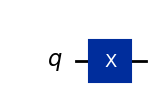

In [ ]:
from qiskit import QuantumCircuit

# Crear un nuevo circuito con 1 qubit
qc = QuantumCircuit(1)

# Aplicar una compuerta X (NOT) al qubit 0
qc.x(0)

# Retorna un dibujo del circuito con MatPlotLib ("mpl").
# Esta es la ultima linea de codigo para que el grafico aparezca en la celda.
qc.draw("mpl")

**NOTA:** Cada vez que uses qiskit en Colab (en una nueva sesión) vamos a tener que instalarlo, ya que no es una librería "preinstalada". Ejecutá las celdas 2 y 3, reiniciá el entorno de ejecución y después verificá ejecutanto la celda 4. Ahora podemos seguir adelante.

In [ ]:
# Configuración general: import y simulador
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit import ClassicalRegister, QuantumRegister

from qiskit_aer import AerSimulator
from qiskit.circuit import Parameter
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import plot_histogram

sim = AerSimulator()

def run_circuit(qc, shots=1024):
    """Transpila y ejecuta un circuito en el simulador AerSimulator, devuelve counts."""
    tqc = transpile(qc, sim)
    result = sim.run(tqc, shots=shots).result()
    return result.get_counts()

## **Día II:** Teleportación Cuántica

La teleportación cuántica es una extensión natural de los conceptos ya vistos: reutiliza el estado de Bell y el mecanismo de Phase Kickback.

### Objetivo

Transmitir un estado cuántico desconocido $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$
desde el qubit de Alice (q0) hasta el qubit de Bob (q2), usando:
- un par de qubits entrelazados compartido previamente (q1 y q2),
- dos bits clásicos de comunicación,
- **sin** enviar el qubit físico de q0 directamente.

### Derivación matemática

**Paso 1 — Estado inicial:** Alice prepara $|\psi\rangle$ en q0; q1 y q2 arrancan en $|00\rangle$.

**Paso 2 — Par de Bell compartido** (H en q1, luego CNOT(q1→q2)):

$$|\psi\rangle \otimes \frac{1}{\sqrt2}(|00\rangle+|11\rangle)$$

**Paso 3 — Alice aplica CNOT(q0→q1) seguido de H(q0)** (el mismo patrón que vimos en
Phase Kickback). Expandiendo con $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$, el estado
conjunto de los 3 qubits se reescribe como:

$$\frac{1}{2}\Big[|00\rangle(\alpha|0\rangle+\beta|1\rangle) + |01\rangle(\alpha|1\rangle+\beta|0\rangle)
+ |10\rangle(\alpha|0\rangle-\beta|1\rangle) + |11\rangle(\alpha|1\rangle-\beta|0\rangle)\Big]$$

donde los dos primeros kets corresponden a los qubits de Alice (q0,q1) y el tercero al
qubit de Bob (q2).

**Paso 4 — Alice mide q0 y q1**, obteniendo $(m_0,m_1)$, y se los comunica a Bob por un
canal clásico.

**Paso 5 — Bob corrige q2** según la tabla:

| $(m_0,m_1)$ | Estado de q2 antes de corregir | Corrección |
|---|---|---|
| 00 | $\alpha\|0\rangle+\beta\|1\rangle$ | ninguna |
| 01 | $\alpha\|1\rangle+\beta\|0\rangle$ | $X$ |
| 10 | $\alpha\|0\rangle-\beta\|1\rangle$ | $Z$ |
| 11 | $\alpha\|1\rangle-\beta\|0\rangle$ | $X$ luego $Z$ |

Tras la corrección, q2 queda exactamente en $\alpha|0\rangle+\beta|1\rangle$: el estado
original ha sido "teleportado", sin que el qubit físico de Alice haya viajado y sin
violar el teorema de no-clonación (el estado original en q0 queda destruido al medir).

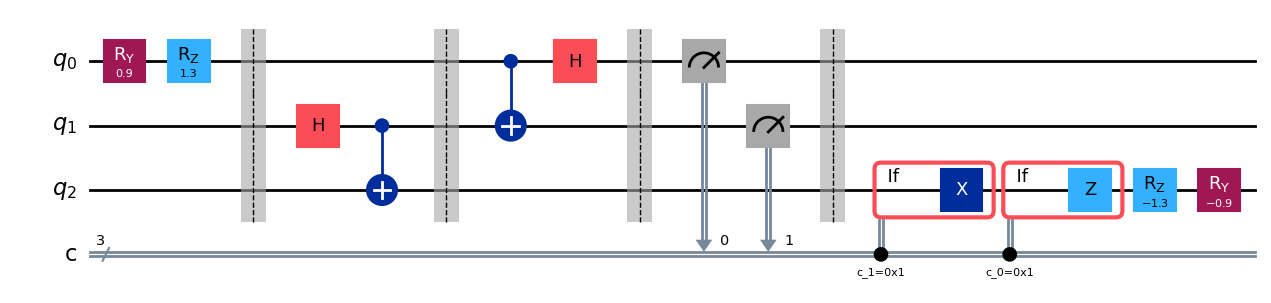

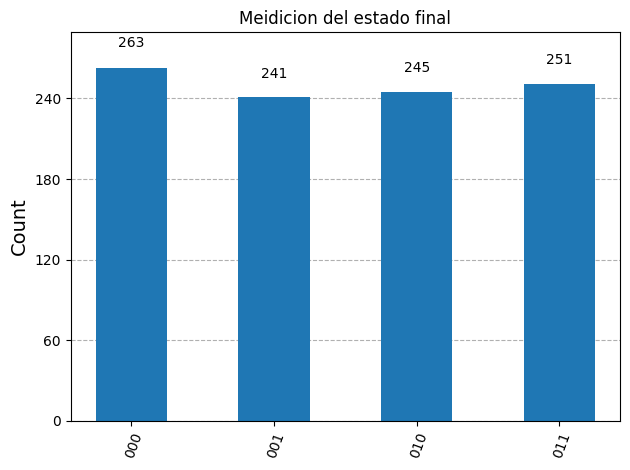

In [ ]:
# Circuito de teleportación cuántica usando corrección condicional basadas en resultados de la medición.
def teleport_circuit(theta, phi):
    """Construye el circuito de teleportación. El estado a teleportar se prepara en q0
    aplicando Ry(theta) y Rz(phi) sobre |0>, lo cual permite generar cualquier estado
    de un qubit, a menos de una fase global."""
    qc = QuantumCircuit(3, 3)

    # Preparar el estado desconocido en q0
    qc.ry(theta, 0)
    qc.rz(phi, 0)
    qc.barrier()

    # Crear el par de Bell compartido entre q1 (Alice) y q2 (Bob)
    qc.h(1)
    qc.cx(1, 2)
    qc.barrier()

    # Alice aplica CNOT(q0->q1) y H(q0)
    qc.cx(0, 1)
    qc.h(0)
    qc.barrier()

    # Alice mide sus dos qubits
    qc.measure(0, 0)
    qc.measure(1, 1)
    qc.barrier()

    # Bob corrige q2 según los bits clásicos de Alice
    with qc.if_test((qc.clbits[1], 1)):
        qc.x(2)
    with qc.if_test((qc.clbits[0], 1)):
        qc.z(2)
    qc.rz(-phi, 2)
    qc.ry(-theta, 2)

    return qc

qc_teleport = teleport_circuit(theta=0.9, phi=1.3)
display(qc_teleport.draw(output='mpl'))
counts = run_circuit(qc_teleport, shots=1000)
plot_histogram(counts, title="Meidicion del estado final")


Podemos verificar el protocolo de la siguiente forma: preparar q0 en un
estado computacional conocido ($|0\rangle$ o $|1\rangle$), correr el protocolo completo, y medir el qubit de Bob al final para confirmar que coincide con lo que Alice quiso enviar.

In [ ]:
def teleport_and_measure(alice_bit):
    qc = QuantumCircuit(3, 3)
    if alice_bit == 1:
        qc.x(0)  # Alice quiere teleportar el estado |1>
    qc.barrier()

    qc.h(1)
    qc.cx(1, 2)
    qc.barrier()

    qc.cx(0, 1)
    qc.h(0)
    qc.barrier()

    qc.measure(0, 0)
    qc.measure(1, 1)
    qc.barrier()

    with qc.if_test((qc.clbits[1], 1)):
        qc.x(2)
    with qc.if_test((qc.clbits[0], 1)):
        qc.z(2)

    qc.measure(2, 2)  # medición final de Bob
    return qc

print("Teleportando el bit clásico 0:")
qc0 = teleport_and_measure(0)
counts0 = run_circuit(qc0, shots=1000)
print("  counts (bit de Bob es el más a la izquierda, c2c1c0):", counts0)

print("\nTeleportando el bit clásico 1:")
qc1 = teleport_and_measure(1)
counts1 = run_circuit(qc1, shots=1000)
print("  counts (bit de Bob es el más a la izquierda, c2c1c0):", counts1)

print("\nEn ambos casos, el bit de Bob (posición más a la izquierda del bitstring)")
print("debe coincidir siempre con el bit que Alice quiso teleportar.")


Teleportando el bit clásico 0:
  counts (bit de Bob es el más a la izquierda, c2c1c0): {'001': 226, '010': 233, '000': 288, '011': 253}

Teleportando el bit clásico 1:
  counts (bit de Bob es el más a la izquierda, c2c1c0): {'111': 240, '110': 246, '101': 291, '100': 223}

En ambos casos, el bit de Bob (posición más a la izquierda del bitstring)
debe coincidir siempre con el bit que Alice quiso teleportar.


## **Día II:** Implementación del Experimento de Stern-Gerlach

En el experimento de Stern-Gerlach, los investigadores no podían especificar el ángulo con el que emergería un vector de momento angular desde el horno. Las orientaciones eran aleatorias. Un análogo razonable de ese experimento sería inicializar aleatoriamente los estados de nuestro qubit y realizar mediciones muchas veces.

### Por qué se usan dos ángulos ($\theta$ y $\phi$) y las compuertas Rx, Rz

Cualquier estado puro de un qubit puede representarse como un punto en la superficie de la **esfera de Bloch**, parametrizado por dos ángulos: $\theta$ (colatitud, respecto al eje $z$) y $\phi$ (azimut, alrededor del eje $z$). Aplicando `Rx(θ)` seguido de `Rz(φ)` sobre el estado inicial $|0\rangle$, podemos alcanzar (hasta una fase global irrelevante) cualquier punto de esa esfera — es decir, cualquier orientación posible del spin. Esto es exactamente lo que necesitamos para modelar un spin que sale del horno apuntando en una dirección arbitraria del espacio.


### Preparación de estados aleatorios

Una vez construido, en los pasos siguientes vamos a generar muchos pares aleatorios $(\theta,\phi)$ — simulando espines que emergen del horno en direcciones al azar —, asignar esos valores al circuito parametrizado, ejecutar la medición sobre el eje $z$ para cada uno, y analizar la distribución resultante de resultados `0`/`1`.

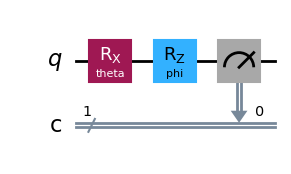

In [ ]:
theta = Parameter("theta")
phi = Parameter("phi")

# Definimos los registros
qr = QuantumRegister(1, "q")
cr = ClassicalRegister(1, "c")
qc = QuantumCircuit(qr, cr)

# Agregamos compuertas de rotación para llevar el estado del qubit 0 a orientaciones aleatorias
qc.rx(theta, 0)
qc.rz(phi, 0)
qc.measure(0, 0)

qc.draw("mpl")

Normalmente, en un circuito cuántico real, fijamos los parámetros del circuito y pedimos muchos `shots` (repeticiones) de la **misma** preparación, para estimar las probabilidades de cada resultado. Acá el enfoque es distinto: en vez de repetir el mismo circuito muchas veces, generamos un circuito **distinto** en cada iteración (con una orientación aleatoria diferente) y le pedimos un único `shot`. Esto modela fielmente el experimento físico: cada partícula que sale del horno tiene una orientación de spin distinta y aleatoria, y solo se mide una vez — no tiene sentido "repetir" la medición de la misma partícula con la misma orientación, porque en el experimento real cada partícula pasa una sola vez por el aparato.

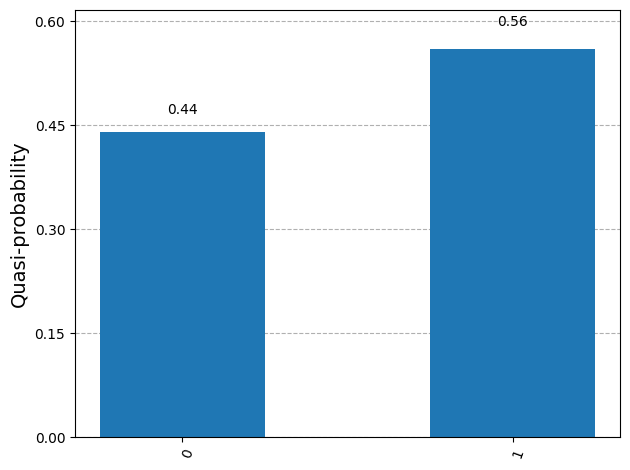

In [ ]:
# Una lista para almacenar las probabilidades acumuladas de los dos posibles resultados de medición.
probslist = {"0": 0.0, "1": 0.0}

# Elegimos cuántas "partículas"/mediciones
measurements = 100
num_shots = 1

for i in range(measurements):
    # Asignamos una orientación aleatoria para cada medición
    theta_val = random.random() * 2 * np.pi
    phi_val = random.random() * 2 * np.pi

    # Usamos un diccionario explícito {parámetro: valor} para evitar ambigüedad de orden
    circuito_asignado = qc.assign_parameters({theta: theta_val, phi: phi_val})

    # Ejecutamos el circuito usando la misma función run_circuit() de los labs anteriores
    counts = run_circuit(circuito_asignado, shots=num_shots)

    # Actualizamos la lista de probabilidades
    zeroterm = counts.get("0", 0)
    oneterm = counts.get("1", 0)
    probslist["0"] += zeroterm
    probslist["1"] += oneterm

probslist["0"] /= measurements
probslist["1"] /= measurements

plot_histogram(probslist)

## **Día II:** Implementación de la Desigualdad de Bell

Referencia: [The nature of quantum states: hidden variables versus Bell's inequality](https://quantum.cloud.ibm.com/learning/en/modules/quantum-mechanics/bells-inequality-with-qiskit)

Definimoss la dirección de la medición de Lucas en $+z$, lo cual es algebraicamente correcto, pero ademas convieniente, ya que las computadoras cuanticas tipicamente miden la proyeccion en $z$.

Queremos construir un circuito cuántico que nos de la misma probabilidad que:

$$
P_{++}=\left|  \left(_L\langle+|_R\left(\cos(\theta/2)\langle+|+\sin(\theta/2)\langle-|\right)\right)  \frac{1}{\sqrt{2}}\left(|+\rangle_L|-\rangle_R-|-\rangle_L|+\rangle_R\right)    \right|^2
$$

A partir de las operaciones de las compuertas anteriormente vistas, podemos ver, por ejemplo, que los kets en las expresiones para $P_{++}$:

$$
\frac{1}{\sqrt{2}}\left(|+\rangle_L|-\rangle_R-|-\rangle_L|+\rangle_R\right)
$$

probablemente involucren una compuerta Hadamard para obtener la superposición, y una compuerta CNOT para crear el entrelazamiento.

Ahora usaremos las compuertas H, X y CNOT para convertir $|0\rangle_L|0\rangle_R$ en $\frac{1}{\sqrt{2}}\left(|+\rangle_L|-\rangle_R-|-\rangle_L|+\rangle_R\right)$:

$$
\frac{1}{\sqrt{2}}\left(|0\rangle_L|1\rangle_R-|1\rangle_L|0\rangle_R\right)
$$

$$
\frac{1}{\sqrt{2}}CNOT_{LR}\left(|0\rangle_L|1\rangle_R-|1\rangle_L|1\rangle_R\right)
$$

Aquí $CNOT_{LR}$ significa una compuerta CNOT que usa L como control y R como objetivo. Ahora podemos factorizar la parte R del estado:

$$
\text{CNOT}_{LR}\frac{1}{\sqrt{2}}\left(|0\rangle_L-|1\rangle_L\right)|1\rangle_R
$$

$$
\text{CNOT}_{LR} H_L|1\rangle_L|1\rangle_R
$$

$$
\text{CNOT}_{LR} H_L X_L X_R|0\rangle_L|0\rangle_R
$$

Ahora hemos escrito el ket enteramente como compuertas cuánticas operando sobre el estado inicial por defecto de los qubits.

Ahora podemos usar $R_y(\theta)$ actuando sobre $\vphantom{p}_L\langle 0|_R\langle 1|$ para obtener el bra en la expresión para $P_{++}$.

$$
\vphantom{p}_L\langle0|_R\left(\cos(\theta/2)\langle0|+\sin(\theta/2)\langle1|\right)
$$

$$
\vphantom{p}_L\langle0|_R\left(|0\rangle \cos(\theta/2)+|1\rangle \sin(\theta/2)\right)^{\dagger}
$$

$$
\vphantom{p}_L\langle0|\left(R_{y,R}(\theta)|0\rangle_R\right)^{\dagger}
$$

$$
\vphantom{p}_L\langle0|_R\langle0|R_{y,R}(-\theta)
$$

Combinando estos resultados, podemos escribir la probabilidad $P_{++}$ como

$$
p_{++}=\left|\vphantom{p}_L\langle0|_R\langle0|R_{y,R}(-\theta)\text{CNOT}_{LR} H_L X_L X_R|0\rangle_L|0\rangle_R\right|^2
$$

Esto nos da instrucciones explícitas sobre cómo construir nuestro circuito cuántico. Aplicaremos compuertas X, H, CNOT y $R_y$ a qubits que representan los estados cuánticos de las partículas medidas por Lucas y Rihanna, y realizaremos mediciones para obtener la probabilidad.

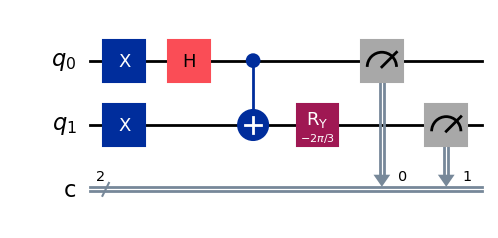

In [ ]:
# Empezamos declarando nuestro primer circuito cuántico, dándole dos qubits (el primer "2") y dos
# bits clásicos para almacenar las salidas (el segundo "2")
# Definimos los registros
qr = QuantumRegister(2, "q")
cr = ClassicalRegister(2, "c")
qc1 = QuantumCircuit(qr, cr)

# Sabemos por nuestro análisis anterior que necesitamos una compuerta X actuando sobre cada uno de los qubits (L y R)
qc1.x([0, 1])
# Necesitamos una compuerta Hadamard actuando sobre el qubit de Lucas, al que llamamos el qubit 0.
qc1.h(0)
# La compuerta controlled-NOT usa el qubit 0 (el de Lucas) como control y el qubit 1 (el de Rihanna)
# como objetivo.
qc1.cx(0, 1)
# La compuerta de rotación actúa sobre el qubit 1 (el de Rihanna) y tiene un argumento de -2 pi/3
qc1.ry(-2 * np.pi / 3, 1)
# Finalmente, queremos medir todos los qubits del circuito para obtener las probabilidades de medición, y
# almacenar los resultados en los bits clásicos.
qc1.measure([0, 1], [0, 1])
# Ahora podemos dibujar el primero de los tres circuitos que verificarán la desigualdad de Bell por nosotros.
qc1.draw(output="mpl")

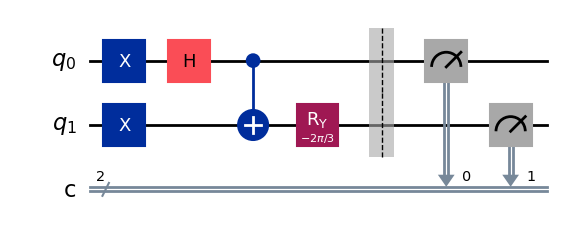

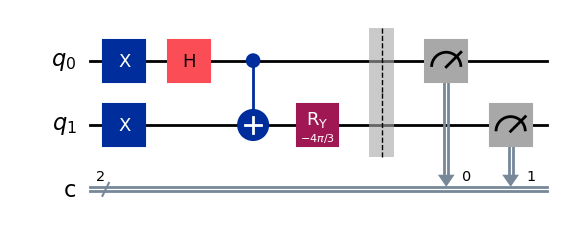

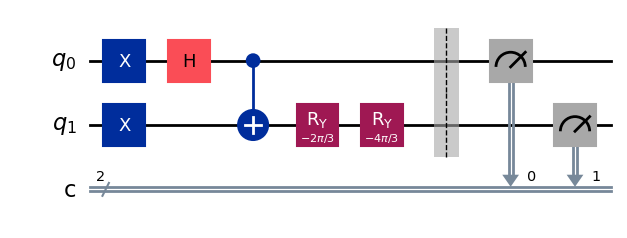

In [ ]:
qcs = [QuantumCircuit(2, 2), QuantumCircuit(2, 2), QuantumCircuit(2, 2)]
for i in range(0, len(qcs)):
    qcs[i].x([0, 1])
    qcs[i].h(0)
    qcs[i].cx(0, 1)

qcs[0].ry(-2 * np.pi / 3, 1)
qcs[1].ry(-4 * np.pi / 3, 1)
qcs[2].ry(-2 * np.pi / 3, 1)
qcs[2].ry(-4 * np.pi / 3, 1)

for i in range(0, len(qcs)):
    qcs[i].barrier()
    qcs[i].measure([0, 1], [0, 1])

counts_list = [None] * len(qcs)

display(qcs[0].draw(output="mpl"))
display(qcs[1].draw(output="mpl"))
display(qcs[2].draw(output="mpl"))

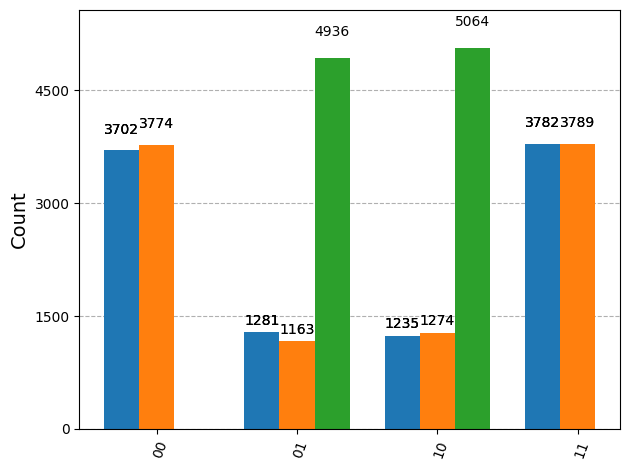

In [ ]:
sampler = StatevectorSampler()

# Iniciamos un trabajo que devolverá shots para los 100 conjuntos de valores de parámetros.
for i in range(0, len(qcs)):
    pub = qcs[i]
    job = sampler.run([pub], shots=10000)
    # Extraemos el resultado para el pub número 0 (este ejemplo tiene un solo pub).
    result = job.result()
    data_pub = result[0].data
    counts = data_pub.c.get_counts()
    counts_list[i] = counts
#    plot_histogram(counts)
plot_histogram(counts_list)

In [ ]:
outcomes = ("00", "01", "10", "11")

# Aquí convertimos los "None" en 0's para poder sumar.

for i in range(0, len(qcs)):
    for j in range(0, len(outcomes)):
        if counts_list[i].get(outcomes[j]) is None:
            counts_list[i].update({outcomes[j]: 0})

# Aquí creamos un diccionario que contiene todos los resultados y suma sus apariciones
# en cada uno de los circuitos.

total_counts = {}
for i in range(0, len(outcomes)):
    total_counts[outcomes[i]] = sum(
        counts_list[j].get(outcomes[i]) for j in range(0, len(qcs))
    )

{'00': 7476, '01': 7380, '10': 7573, '11': 7571}


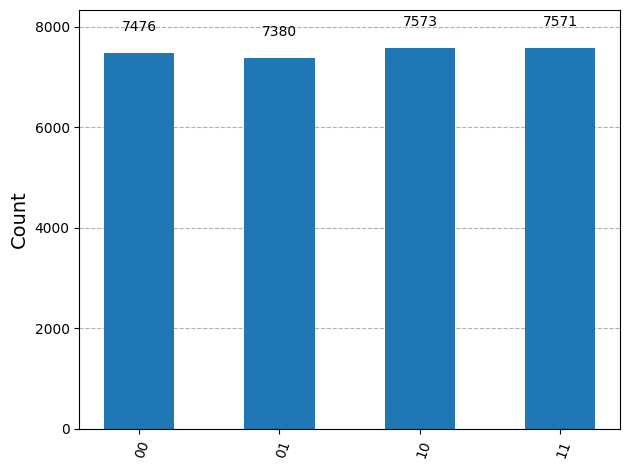

In [ ]:
print(total_counts)
plot_histogram(total_counts)

## **Dia II:** Distribución Cuántica de Claves y Protocolo BB84

### **Experimento 1:** Alice y Bob usan la misma base

Si Alice y Bob eligen la misma base (`Z` o `H`), Bob siempre recupera el bit que Alice envió.

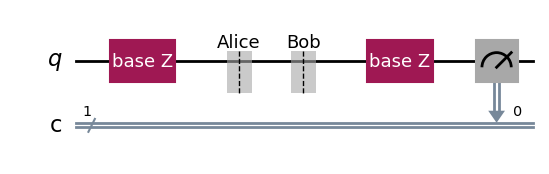

Alice bit=0, base=0 | Bob (misma base) obtiene: 0


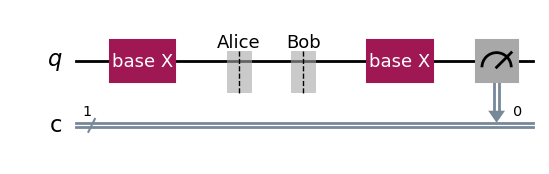

Alice bit=0, base=1 | Bob (misma base) obtiene: 0


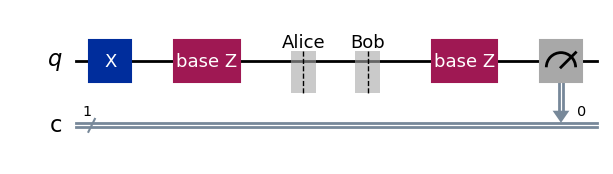

Alice bit=1, base=0 | Bob (misma base) obtiene: 1


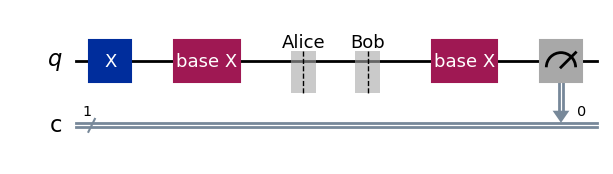

Alice bit=1, base=1 | Bob (misma base) obtiene: 0


In [ ]:
def bb84_single_qubit(alice_bit, alice_basis, bob_basis):
    """alice_basis/bob_basis: 0 = base Z (computacional), 1 = base X (Hadamard)."""
    qc = QuantumCircuit(1, 1)
    base_X = QuantumCircuit(1, name="base X")
    base_Z = QuantumCircuit(1, name="base Z")
    if alice_bit == 1:
        qc.x(0)
    if alice_basis == 0:
        qc.append(base_Z.to_instruction(), [0])
        qc.barrier(label="Alice")
        qc.barrier(label="Bob")
    if alice_basis == 1:
        base_X.h(0)
        qc.append(base_X.to_instruction(), [0])
        qc.barrier(label="Alice")
        qc.barrier(label="Bob")
    if bob_basis == 0:
        qc.append(base_Z.to_instruction(), [0])
    if bob_basis == 1:
        base_X.h(0)
        qc.append(base_X.to_instruction(), [0])
    qc.measure(0, 0)
    display(qc.draw(output='mpl'))
    result = run_circuit(qc, shots=1)
    return qc, int(list(result.keys())[0])

# Mismas bases: Bob siempre obtiene el bit de Alice
for bit in [0, 1]:
    for basis in [0, 1]:
        qc, bob_bit = bb84_single_qubit(bit, basis, basis)
        print(f"Alice bit={bit}, base={basis} | Bob (misma base) obtiene: {bob_bit}")


### **Experimento 2:** Emulación completa de BB84 (sin interceptación de Eve)

Generamos `n` bits aleatorios y bases aleatorias para Alice y Bob, simulamos qubit por qubit, y extraemos la clave a partir de las posiciones donde ambos usaron la misma base.

Alice bits : [0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0] ...
Alice bases: [1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1] ...
Bob bases  : [1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1] ...
Bob results: [0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0] ...

Posiciones con base coincidente: [0, 2, 3, 5, 6, 8, 10, 15, 17, 19, 20, 23, 24, 26, 27, 29] ...
Clave de Alice (bases coincidentes): [0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0] ...
Clave de Bob   (bases coincidentes): [0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0] ...
¿Las claves coinciden? True

Medicion de Bob, en caso de elegir la base erronea: {'0': 237, '1': 248}


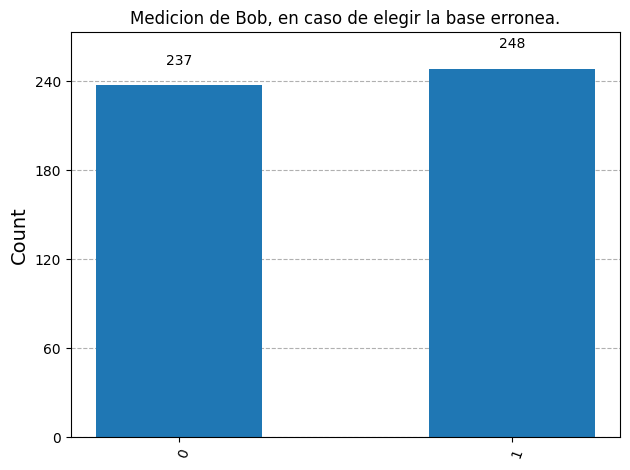

In [ ]:
random.seed(42)
n = 1024  # numero de bits a transmitir

alice_bits  = [random.randint(0, 1) for _ in range(n)]
alice_bases = [random.randint(0, 1) for _ in range(n)]   # 0=Z, 1=X
bob_bases   = [random.randint(0, 1) for _ in range(n)]   # 0=Z, 1=X
bob_results = []

# 1. Construir todos los circuitos (uno por bit, 1 shot cada uno)
circuits = []
for i in range(n):
    qc = QuantumCircuit(1, 1)
    if alice_bits[i] == 1:
        qc.x(0)
    if alice_bases[i] == 1:
        qc.h(0)
    if bob_bases[i] == 1:
        qc.h(0)
    qc.measure(0, 0)
    circuits.append(qc)

# 2. Transpilar todos de una vez y correr en un solo job
tqcs = transpile(circuits, sim)
job = sim.run(tqcs, shots=1)
result = job.result()

# 3. Extraer el resultado de cada circuito individual
bob_results = [int(list(result.get_counts(i).keys())[0]) for i in range(n)]

print("Alice bits :", alice_bits[:16], "...")
print("Alice bases:", alice_bases[:16], "...")
print("Bob bases  :", bob_bases[:16], "...")
print("Bob results:", bob_results[:16], "...")

# 4. Posiciones donde coinciden las bases
matching_idx = [i for i in range(n) if alice_bases[i] == bob_bases[i]]
key_alice = [alice_bits[i] for i in matching_idx]
key_bob   = [bob_results[i] for i in matching_idx]

print("\nPosiciones con base coincidente:", matching_idx[:16], "...")
print("Clave de Alice (bases coincidentes):", key_alice[:16], "...")
print("Clave de Bob   (bases coincidentes):", key_bob[:16], "...")
print("¿Las claves coinciden?", key_alice == key_bob)

# 4. Si las bases no coinciden
histograma = {'0':0,'1':0}
for i in range(n):
  if alice_bases[i] != bob_bases[i]:
    if bob_results[i] == 0:
      histograma['0'] += 1
    else:
      histograma['1'] += 1

print("\nMedicion de Bob, en caso de elegir la base erronea:", histograma)
plot_histogram(histograma, title="Medicion de Bob, en caso de elegir la base erronea.")

### **Experimento 3:** Emulación de la interceptación de Eve

Ahora Eve intercepta cada qubit, elige una base aleatoria, mide, y reenvía el qubit a Bob usando la base que ella midió. Si Eve elige la base incorrecta, Bob tiene solo 50% de probabilidad de recuperar el bit correcto de Alice, lo cual introduce errores detectables en la comparación de un subconjunto de la clave.


In [ ]:
random.seed(7)
n = 1024   # numero de bits a transmitir

alice_bits  = [random.randint(0, 1) for _ in range(n)]
alice_bases = [random.randint(0, 1) for _ in range(n)]
eve_bases   = [random.randint(0, 1) for _ in range(n)]
bob_bases   = [random.randint(0, 1) for _ in range(n)]

# Etapa 1: Alice prepara, Eve intercepta y mide (batch completo)
eve_circuits = []
for i in range(n):
    qc = QuantumCircuit(1, 1)
    if alice_bits[i] == 1:
        qc.x(0)
    if alice_bases[i] == 1:
        qc.h(0)
    if eve_bases[i] == 1:
        qc.h(0)
    qc.measure(0, 0)
    eve_circuits.append(qc)

tqcs_eve = transpile(eve_circuits, sim)
result_eve = sim.run(tqcs_eve, shots=1).result()
eve_bits = [int(list(result_eve.get_counts(i).keys())[0]) for i in range(n)]

# Etapa 2: Eve reenvía, Bob mide (batch completo)
bob_circuits = []
for i in range(n):
    qc2 = QuantumCircuit(1, 1)
    if eve_bits[i] == 1:
        qc2.x(0)
    if eve_bases[i] == 1:
        qc2.h(0)
    if bob_bases[i] == 1:
        qc2.h(0)
    qc2.measure(0, 0)
    bob_circuits.append(qc2)

tqcs_bob = transpile(bob_circuits, sim)
result_bob = sim.run(tqcs_bob, shots=1).result()
bob_results = [int(list(result_bob.get_counts(i).keys())[0]) for i in range(n)]

print("Alice bits :", alice_bits[:16], "...")
print("Alice bases:", alice_bases[:16], "...")
print("Eve bases  :", eve_bases[:16], "...")
print("Bob bases  :", bob_bases[:16], "...")
print("Bob results:", bob_results[:16], "...")

matching_idx = [i for i in range(n) if alice_bases[i] == bob_bases[i]]
key_alice = [alice_bits[i] for i in matching_idx]
key_bob   = [bob_results[i] for i in matching_idx]
errors = sum(1 for a, b in zip(key_alice, key_bob) if a != b)

print("\nClave de Alice:", key_alice[:16], "...")
print("Clave de Bob  :", key_bob[:16], "...")
print(f"Errores detectados: {errors}/{len(key_alice)} "
      f"(evidencia de eavesdropping si Eve adivinó mal la base)")

Alice bits : [1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0] ...
Alice bases: [1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1] ...
Eve bases  : [0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1] ...
Bob bases  : [1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0] ...
Bob results: [1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1] ...

Clave de Alice: [1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0] ...
Clave de Bob  : [1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0] ...
Errores detectados: 127/541 (evidencia de eavesdropping si Eve adivinó mal la base)


> **Nota:** El protocolo Ekert91 (basado en pares entrelazados y el test de Bell,
> con bases a 0°, 120°, 240°) se describe en las referencias como una extensión de los mismos
> conceptos de esta sección.

 ## **Referencias**

Notebook basada en el paper **"Understanding Quantum Parallelism through Programming"** (Sang & Yu, CSCI 2023), implementando en **Qiskit 2.4.2** los circuitos descritos en la Sección III, Labs 1 a 7. Se han agregado experimentos adicionales para incorporar otros temas.